# code_035 · Fair comparisons and ablation

**Book:** section 7.4. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_07_GUIDE.md), [execution evidence](../CHAPTER_07_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_035). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=735;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 735


<a id="contract"></a>
## Compare the component, not the name

Eighty independent ten-node cycle graphs represent synthetic structures. Each node has two dimensionless measurements. The known adjacency averages its two neighbors; no edge connects different graphs. Response is .7*x0+.9*neighbor_mean0+.3*x0*neighbor_mean1 plus noise sd .1 mm. Graphs 0–47/48–63/64–79 train/develop/assess. Both graph and relational predictors receive the same node features and available topology. Scaler fits training nodes only; graph IDs define the split.

A real one-hop graph rule computes h=tanh(x@Ws+mean_neighbor(x)@Wn+b), then y=h@v+c. A relational table explicitly stores [x,mean_neighbor(x)] and uses a tanh hidden layer. These are mathematically equivalent parameterizations, so the matched experiment should reveal no architecture-name advantage. Hidden width 8 gives 49 trainable coefficients in each. Frozen adjacency/features make cached neighbor means legitimate for both; no assessment labels enter them.

Both receive the same five initializations, rate .03, 250 full-batch updates, checkpoints [50,250] and development graph-averaged MAE selection over the mean of all five seeds. No best seed is selected. Ablations replace neighbor features by zeros or a fixed within-graph permutation; they test information alignment rather than another architecture.


In [2]:
from sklearn.preprocessing import StandardScaler
G=80;nodes=10;A=np.zeros((nodes,nodes))
for i in range(nodes):A[i,(i-1)%nodes]=.5;A[i,(i+1)%nodes]=.5
raw=rng.normal(size=(G,nodes,2));mean_raw=np.einsum('ij,gjk->gik',A,raw)
y=.7*raw[:,:,0]+.9*mean_raw[:,:,0]+.3*raw[:,:,0]*mean_raw[:,:,1]+rng.normal(0,.1,(G,nodes))
train_graphs=np.arange(48);dev_graphs=np.arange(48,64);final_graphs=np.arange(64,80)
scaler=StandardScaler().fit(raw[train_graphs].reshape(-1,2));X=scaler.transform(raw.reshape(-1,2)).reshape(G,nodes,2);M=np.einsum('ij,gjk->gik',A,X)
shuffled=np.stack([M[g,rng.permutation(nodes)] for g in range(G)])
Zfull=np.concatenate([X,M],axis=2);Zown=np.concatenate([X,np.zeros_like(M)],axis=2);Zshuffle=np.concatenate([X,shuffled],axis=2)
assert np.allclose(A.sum(1),1) and np.allclose(A,A.T)
assert not set(train_graphs)&set(dev_graphs) and not set(train_graphs)&set(final_graphs) and not set(dev_graphs)&set(final_graphs)
assert np.allclose(scaler.mean_,raw[train_graphs].reshape(-1,2).mean(0))
assert (2*8+2*8+8+8+1)==(4*8+8+8+1)==49


<a id="matched"></a>
## Two implemented forward/backward paths

The graph path keeps self and neighbor weights separate; the relational path uses one concatenated matrix. Both apply the same full-batch half-MSE gradient. Initial arrays are copied, not separately sampled, to isolate parameterization. Actual graph prediction recomputes the neighbor aggregation from input nodes and adjacency. Check fitted predictions and parameters at each eligible checkpoint; roundoff agreement does not claim that every GNN is equivalent to every tabular model.


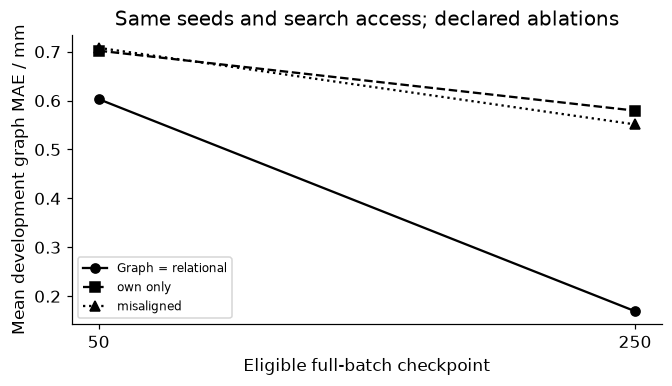

In [3]:
def clone(p):return {k:v.copy() for k,v in p.items()}
def graph_predict(p,x,adjacency):
 m=np.einsum('ij,gjk->gik',adjacency,x)
 return np.tanh(x@p['self']+m@p['neighbor']+p['b'])@p['v']+p['c']
def dense_predict(p,z):return np.tanh(z@p['W']+p['b'])@p['v']+p['c']
def graph_step(p,x,m,target,rate):
 h=np.tanh(x@p['self']+m@p['neighbor']+p['b']);r=(h@p['v']+p['c']-target)/len(target);dh=r[:,None]*p['v'][None,:]*(1-h*h)
 gs=x.T@dh;gn=m.T@dh;gb=dh.sum(0);gv=h.T@r;gc=r.sum()
 p['self']-=rate*gs;p['neighbor']-=rate*gn;p['b']-=rate*gb;p['v']-=rate*gv;p['c']-=rate*gc
def dense_step(p,z,target,rate):
 h=np.tanh(z@p['W']+p['b']);r=(h@p['v']+p['c']-target)/len(target);dh=r[:,None]*p['v'][None,:]*(1-h*h)
 gW=z.T@dh;gb=dh.sum(0);gv=h.T@r;gc=r.sum()
 p['W']-=rate*gW;p['b']-=rate*gb;p['v']-=rate*gv;p['c']-=rate*gc
seeds=[0,1,2,3,4];checkpoints=[50,250];all_states=[];dev_scores={name:[] for name in ['graph','relational','own_only','misaligned']};max_equivalence=0.
xt=X[train_graphs].reshape(-1,2);mt=M[train_graphs].reshape(-1,2);yt=y[train_graphs].ravel()
for seed in seeds:
 r=np.random.default_rng(SEED+seed);W=r.normal(0,.15,(4,8));v=r.normal(0,.15,8)
 graph={'self':W[:2].copy(),'neighbor':W[2:].copy(),'b':np.zeros(8),'v':v.copy(),'c':np.array(0.)}
 initial={'W':W.copy(),'b':np.zeros(8),'v':v.copy(),'c':np.array(0.)};states={'graph':graph,'relational':clone(initial),'own_only':clone(initial),'misaligned':clone(initial)};saved={}
 for step in range(1,251):
  graph_step(graph,xt,mt,yt,.03)
  for name,z in [('relational',Zfull),('own_only',Zown),('misaligned',Zshuffle)]:dense_step(states[name],z[train_graphs].reshape(-1,4),yt,.03)
  if step in checkpoints:
   assert np.allclose(np.vstack([graph['self'],graph['neighbor']]),states['relational']['W'],atol=1e-12)
   assert np.allclose(graph['v'],states['relational']['v'],atol=1e-12)
   saved[step]={name:clone(p) for name,p in states.items()}
 all_states.append(saved)
 for name in states:
  scores=[]
  for step in checkpoints:
   p=saved[step][name];prediction=graph_predict(p,X[dev_graphs],A) if name=='graph' else dense_predict(p,{'relational':Zfull,'own_only':Zown,'misaligned':Zshuffle}[name][dev_graphs])
   scores.append(float(np.mean(np.mean(abs(prediction-y[dev_graphs]),axis=1))))
  dev_scores[name].append(scores)
selected={name:checkpoints[int(np.argmin(np.mean(scores,axis=0)))] for name,scores in dev_scores.items()}
assert selected['graph']==selected['relational'] and np.allclose(dev_scores['graph'],dev_scores['relational'])
fig,ax=plt.subplots(figsize=(6,3.4))
for name,style,marker in [('graph','-','o'),('own_only','--','s'),('misaligned',':','^')]:ax.plot(checkpoints,np.mean(dev_scores[name],axis=0),color='black',ls=style,marker=marker,label='Graph = relational' if name=='graph' else name.replace('_',' '))
ax.set(xticks=checkpoints,xlabel='Eligible full-batch checkpoint',ylabel='Mean development graph MAE / mm',title='Same seeds and search access; declared ablations');ax.legend(fontsize=8);plt.show()
RESULTS['selected_steps']=selected;RESULTS['development_MAE_by_seed_checkpoint_mm']=dev_scores


<a id="attempts"></a>
## Keep a rejected attempt in the record

Separate deliberate failure check: rate 10000 on the same training objective. Stop if half MSE exceeds 1e8, before uncontrolled overflow; this is not an eligible development candidate and not a hidden search trial. Report the failure and its bounded stop criterion. The eligible comparison still uses exactly two checkpoints and five initializations per family.


In [4]:
failed=clone(initial);failure_loss=0.;rejected=False
for attempt_step in range(20):
 dense_step(failed,Zfull[train_graphs].reshape(-1,4),yt,10000.)
 failure_loss=float(.5*np.mean((dense_predict(failed,Zfull[train_graphs])-y[train_graphs])**2))
 if not np.isfinite(failure_loss) or failure_loss>1e8:rejected=True;break
assert rejected and np.isfinite(failure_loss)
ledger={'eligible_families':4,'initializations_per_family':5,'eligible_checkpoints':[50,250],'maximum_updates_per_fit':250,'hidden_width':8,'parameters_each':49,'rejected_rate':10000,'failure_stop_half_MSE_mm2':failure_loss,'failure_steps':attempt_step+1}
RESULTS['trial_ledger']=ledger;display(pd.DataFrame(ledger.items(),columns=['record','value']))


,record,value
0,eligible_families,4
1,initializations_per_family,5
2,eligible_checkpoints,"[50, 250]"
3,maximum_updates_per_fit,250
4,hidden_width,8
5,parameters_each,49
6,rejected_rate,10000
7,failure_stop_half_MSE_mm2,4943365127522707.0
8,failure_steps,2


<a id="final"></a>
## Paired final results, all seeds retained

Freeze each family's development-selected checkpoint. Assess sixteen new final graphs, averaging node errors within graphs and then equally across graphs. Report every seed and the paired graph-versus-relational difference. Shared graphs and starts make this a controlled comparison of the specified implementation. Runtime, additional searches and unrelated architecture families are not being ranked.


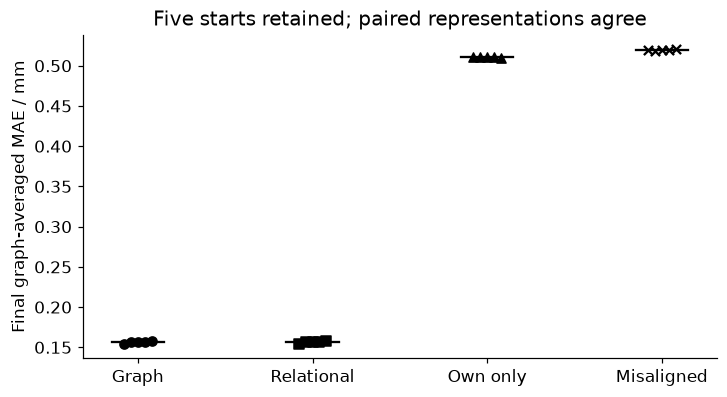

{'selected_steps': {'graph': 250, 'relational': 250, 'own_only': 250, 'misaligned': 250}, 'development_MAE_by_seed_checkpoint_mm': {'graph': [[0.6352449772113465, 0.16694191801890126], [0.6548641168821047, 0.16763463086615146], [0.5774028278159155, 0.16835341166820106], [0.6634227794932757, 0.17320064812093283], [0.4838465963337252, 0.17054983202913962]], 'relational': [[0.6352449772113465, 0.16694191801890124], [0.6548641168821048, 0.16763463086615146], [0.5774028278159155, 0.16835341166820106], [0.6634227794932757, 0.17320064812093283], [0.4838465963337251, 0.17054983202913962]], 'own_only': [[0.6706391876435512, 0.578204944210567], [0.7511559298587935, 0.5798157701501261], [0.6484238010292248, 0.578944092551771], [0.7498472365016373, 0.5787965030143546], [0.6898250866523753, 0.5815102235368352]], 'misaligned': [[0.7048997311464436, 0.5501434077213315], [0.7449697575841023, 0.5473418930224733], [0.6714061749477499, 0.5537906991702594], [0.7437771252286101, 0.5526960257412132], [0.674

In [5]:
final_scores={name:[] for name in selected};equivalence=[]
for saved in all_states:
 gp=graph_predict(saved[selected['graph']]['graph'],X[final_graphs],A)
 dp=dense_predict(saved[selected['relational']]['relational'],Zfull[final_graphs]);equivalence.append(float(np.max(abs(gp-dp))))
 for name in selected:
  prediction=gp if name=='graph' else dense_predict(saved[selected[name]][name],{'relational':Zfull,'own_only':Zown,'misaligned':Zshuffle}[name][final_graphs])
  final_scores[name].append(float(np.mean(np.mean(abs(prediction-y[final_graphs]),axis=1))))
assert max(equivalence)<1e-10 and np.allclose(final_scores['graph'],final_scores['relational'],atol=1e-12)
assert all(len(v)==5 and np.isfinite(v).all() for v in final_scores.values())
fig,ax=plt.subplots(figsize=(6.5,3.5))
for i,(name,scores) in enumerate(final_scores.items()):ax.scatter(np.full(5,i)+np.linspace(-.08,.08,5),scores,marker=['o','s','^','x'][i],color='black');ax.plot([i-.15,i+.15],[np.mean(scores)]*2,'k-')
ax.set(xticks=np.arange(4),xticklabels=['Graph','Relational','Own only','Misaligned'],ylabel='Final graph-averaged MAE / mm',title='Five starts retained; paired representations agree');plt.show()
RESULTS['final_MAE_by_seed_mm']=final_scores;RESULTS['maximum_graph_relational_prediction_difference_mm']=max(equivalence);print(RESULTS)


<a id="exercises"></a>
## Exercises and hints

1. Add two-hop message passing and give a relational baseline the same two-hop features before attributing a gain to architecture.
2. Match total search effort as well as per-fit updates. Record hardware and wall time if making throughput claims.
3. Change graph sizes and compare node-weighted versus graph-weighted metrics.
4. Add unavailable future edges and show why matching a leaky information set does not make a useful comparison.
5. Replicate on new topology families and observed structures without selecting the best seed.

**Hints:** ablation estimates a change in this pipeline under this budget. Nonlinearities between multiple message-passing steps need not reduce to one fixed neighbor summary. This is an actual one-hop shared-weight graph computation and its mathematically matched table rule, not a claimed general equivalence between all GNNs and tabular learners. Inspect data, split, features, topology, loss, search and seeds together.


In [6]:
summary={'example_id':'code_035','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['actual one-hop graph and matched relational predictor', 'equal data features parameter and search access', 'predeclared repeated initializations', 'aligned-neighbor ablations', 'failed-attempt ledger and fixed paired final assessment'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["actual one-hop graph and matched relational predictor", "equal data features parameter and search access", "predeclared repeated initializations", "aligned-neighbor ablations", "failed-attempt ledger and fixed paired final assessment"], "elapsed_seconds": 0.341, "example_id": "code_035", "hardware": "Darwin arm64 CPU", "results": {"development_MAE_by_seed_checkpoint_mm": {"graph": [[0.6352449772113465, 0.16694191801890126], [0.6548641168821047, 0.16763463086615146], [0.5774028278159155, 0.16835341166820106], [0.6634227794932757, 0.17320064812093283], [0.4838465963337252, 0.17054983202913962]], "misaligned": [[0.7048997311464436, 0.5501434077213315], [0.7449697575841023, 0.5473418930224733], [0.6714061749477499, 0.5537906991702594], [0.7437771252286101, 0.5526960257412132], [0.6742107018284826, 0.5523989154382886]], "own_only": [[0.6706391876435512, 0.578204944210567], [0.7511559298587935, 0.5798157701501261], [0.6484238010292248, 0.578